[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-3/time-travel.ipynb) [![Abrir en LangChain Academy](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58239536-lesson-5-time-travel)

# Time travel

## Repaso

Vimos las motivaciones del human-in-the-loop:

(1) `Aprobación`: podemos interrumpir al agente, mostrarle el estado a una persona y dejar que acepte una acción.

(2) `Depuración`: podemos retroceder en el grafo para reproducir o evitar problemas.

(3) `Edición`: podemos modificar el estado.

Vimos cómo los breakpoints pueden detener el grafo en nodos específicos o dejar que se interrumpa dinámicamente a sí mismo.

Luego mostramos cómo continuar con la aprobación humana o editar directamente el estado del grafo con feedback humano.

## Objetivos

Ahora veamos cómo LangGraph [facilita la depuración](https://docs.langchain.com/oss/python/langgraph/use-time-travel): puedes ver estados pasados, repetirlos (*replay*) e incluso bifurcarlos (*fork*).

A esto lo llamamos `time travel`.

In [ ]:
%%capture --no-stderr
%pip install --quiet -U langgraph langchain_openai langgraph_sdk langgraph-prebuilt

In [ ]:
import os, getpass

def _definir_variable(variable: str):
    if not os.environ.get(variable):
        os.environ[variable] = getpass.getpass(f"{variable}: ")

_definir_variable("OPENAI_API_KEY")

Construyamos nuestro agente.

In [1]:
from langchain_openai import ChatOpenAI

def multiplicar(a: int, b: int) -> int:
    """Multiplica a y b.

    Args:
        a: primer entero
        b: segundo entero
    """
    return a * b

# Esta será una herramienta
def sumar(a: int, b: int) -> int:
    """Suma a y b.

    Args:
        a: primer entero
        b: segundo entero
    """
    return a + b

def dividir(a: int, b: int) -> float:
    """Divide a entre b.

    Args:
        a: primer entero
        b: segundo entero
    """
    return a / b

herramientas = [sumar, multiplicar, dividir]
llm = ChatOpenAI(model="gpt-4o")
llm_con_herramientas = llm.bind_tools(herramientas)

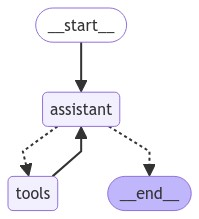

In [2]:
from IPython.display import Image, display

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState
from langgraph.graph import START, END, StateGraph
from langgraph.prebuilt import tools_condition, ToolNode

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

# Mensaje de sistema
mensaje_sistema = SystemMessage(content="Eres un asistente útil encargado de realizar operaciones aritméticas con un conjunto de entradas.")

# Nodo
def asistente(estado: MessagesState):
   return {"messages": [llm_con_herramientas.invoke([mensaje_sistema] + estado["messages"])]}

# Grafo
constructor = StateGraph(MessagesState)

# Definimos los nodos: son los que hacen el trabajo
constructor.add_node("asistente", asistente)
constructor.add_node("tools", ToolNode(herramientas))

# Definimos las aristas: determinan el flujo de control
constructor.add_edge(START, "asistente")
constructor.add_conditional_edges(
    "asistente",
    # Si el último mensaje (resultado) del asistente es una llamada a herramienta -> tools_condition dirige a tools
    # Si el último mensaje (resultado) del asistente no es una llamada a herramienta -> tools_condition dirige a END
    tools_condition,
)
constructor.add_edge("tools", "asistente")

memoria = MemorySaver()
grafo = constructor.compile(checkpointer=MemorySaver())

# Mostramos el grafo
display(Image(grafo.get_graph(xray=True).draw_mermaid_png()))

Ejecutémoslo, como antes.

In [3]:
# Entrada
entrada_inicial = {"messages": HumanMessage(content="Multiplica 2 y 3")}

# Hilo
hilo = {"configurable": {"thread_id": "1"}}

# Ejecutamos el grafo hasta la primera interrupción
for evento in grafo.stream(entrada_inicial, hilo, stream_mode="values"):
    evento['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_ikJxMpb777bKMYgmM3d9mYjW)
 Call ID: call_ikJxMpb777bKMYgmM3d9mYjW
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6
================================== Ai Message ==================================

The result of multiplying 2 and 3 is 6.


## Explorar el historial

Podemos usar `get_state` para ver el estado **actual** de nuestro grafo, dado el `thread_id`.

In [4]:
grafo.get_state({'configurable': {'thread_id': '1'}})

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 2 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_ikJxMpb777bKMYgmM3d9mYjW', 'function': {'arguments': '{"a":2,"b":3}', 'name': 'multiply'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 131, 'total_tokens': 148}, 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run-bc24d334-8013-4f85-826f-e1ed69c86df0-0', tool_calls=[{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_ikJxMpb777bKMYgmM3d9mYjW', 'type': 'tool_call'}], usage_metadata={'input_tokens': 131, 'output_tokens': 17, 'total_tokens': 148}), ToolMessage(content='6', name='multiply', id='1012611a-30c5-4732-b789-8c455580c7b4', tool_call_id='call_ikJxMpb777bKMYgmM3d9mYjW'), AIMessage(content='The result of multiplying 2 and 3 is 6.', addition

También podemos explorar el historial de estados de nuestro agente.

`get_state_history` nos entrega el estado en todos los pasos anteriores.

In [5]:
todos_los_estados = [e for e in grafo.get_state_history(hilo)]

In [6]:
len(todos_los_estados)

5

El primer elemento es el estado actual, igual que el que obtuvimos con `get_state`.

In [7]:
todos_los_estados[-2]

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 2 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]}, next=('assistant',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a440-a003-6c74-8000-8a2d82b0d126'}}, metadata={'source': 'loop', 'writes': None, 'step': 0, 'parents': {}}, created_at='2024-09-03T22:29:52.988265+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a440-9ffe-6512-bfff-9e6d8dc24bba'}}, tasks=(PregelTask(id='ca669906-0c4f-5165-840d-7a6a3fce9fb9', name='assistant', error=None, interrupts=(), state=None),))

Todo lo anterior lo podemos visualizar aquí:

![fig1.jpg: historial de estados del agente](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbb038211b544898570be3_time-travel1.png)

## Repetir (*replay*)

Podemos volver a ejecutar nuestro agente desde cualquiera de los pasos anteriores.

![fig2.jpg: repetir la ejecución desde un paso anterior](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbb038a0bd34b541c78fb8_time-travel2.png)

Volvamos al paso que recibió la entrada humana.

In [8]:
a_repetir = todos_los_estados[-2]

In [9]:
a_repetir

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 2 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]}, next=('assistant',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a440-a003-6c74-8000-8a2d82b0d126'}}, metadata={'source': 'loop', 'writes': None, 'step': 0, 'parents': {}}, created_at='2024-09-03T22:29:52.988265+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a440-9ffe-6512-bfff-9e6d8dc24bba'}}, tasks=(PregelTask(id='ca669906-0c4f-5165-840d-7a6a3fce9fb9', name='assistant', error=None, interrupts=(), state=None),))

Veamos el estado.

In [10]:
a_repetir.values

{'messages': [HumanMessage(content='Multiply 2 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]}

Podemos ver el siguiente nodo que se llamará.

In [11]:
a_repetir.next

('assistant',)

También obtenemos el config, que nos indica el `checkpoint_id` y el `thread_id`.

In [12]:
a_repetir.config

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1ef6a440-a003-6c74-8000-8a2d82b0d126'}}

Para repetir desde aquí, simplemente le pasamos el config de vuelta al agente.

El grafo sabe que este checkpoint ya se ejecutó.

¡Simplemente lo repite desde este checkpoint!

In [13]:
for evento in grafo.stream(None, a_repetir.config, stream_mode="values"):
    evento['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_SABfB57CnDkMu9HJeUE0mvJ9)
 Call ID: call_SABfB57CnDkMu9HJeUE0mvJ9
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6
================================== Ai Message ==================================

The result of multiplying 2 and 3 is 6.


Ahora podemos ver nuestro estado actual después de que el agente se volvió a ejecutar.

## Bifurcar (*fork*)

¿Y si queremos ejecutar desde ese mismo paso, pero con una entrada distinta?

Eso es bifurcar.

![fig3.jpg: bifurcar el estado desde un paso anterior](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbb038f89f2d847ee5c336_time-travel3.png)

In [14]:
a_bifurcar = todos_los_estados[-2]
a_bifurcar.values["messages"]

[HumanMessage(content='Multiply 2 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]

De nuevo, tenemos el config.

In [15]:
a_bifurcar.config

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1ef6a440-a003-6c74-8000-8a2d82b0d126'}}

Modifiquemos el estado en este checkpoint.

Basta con ejecutar `update_state` indicando el `checkpoint_id`.

Recuerda cómo funciona nuestro *reducer* sobre `messages`:

* Agrega el mensaje, a menos que entreguemos el ID de un mensaje existente.
* Entregamos el ID del mensaje para sobrescribirlo, en lugar de agregarlo al estado.

Entonces, para sobrescribir el mensaje, solo entregamos su ID, que obtenemos con `a_bifurcar.values["messages"][0].id`.

In [16]:
config_bifurcacion = grafo.update_state(
    a_bifurcar.config,
    {"messages": [HumanMessage(content='Multiplica 5 y 3',
                               id=a_bifurcar.values["messages"][0].id)]},
)

In [17]:
config_bifurcacion

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1ef6a442-3661-62f6-8001-d3c01b96f98b'}}

Esto crea un nuevo checkpoint bifurcado.

Pero los metadatos (por ejemplo, hacia dónde ir después) se conservan.

Vemos que el estado actual de nuestro agente se actualizó con la bifurcación.

In [18]:
todos_los_estados = [estado for estado in grafo.get_state_history(hilo) ]
todos_los_estados[0].values["messages"]

[HumanMessage(content='Multiply 5 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]

In [19]:
grafo.get_state({'configurable': {'thread_id': '1'}})

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 5 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]}, next=('assistant',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a442-3661-62f6-8001-d3c01b96f98b'}}, metadata={'source': 'update', 'step': 1, 'writes': {'__start__': {'messages': [HumanMessage(content='Multiply 5 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d')]}}, 'parents': {}}, created_at='2024-09-03T22:30:35.598707+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1ef6a440-a003-6c74-8000-8a2d82b0d126'}}, tasks=(PregelTask(id='f8990132-a8d3-5ddd-8d9e-1efbfc220da1', name='assistant', error=None, interrupts=(), state=None),))

Ahora, cuando transmitimos, el grafo sabe que este checkpoint nunca se ejecutó.

Por eso el grafo se ejecuta, en lugar de simplemente repetir.

In [20]:
for evento in grafo.stream(None, config_bifurcacion, stream_mode="values"):
    evento['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 5 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_KP2CVNMMUKMJAQuFmamHB21r)
 Call ID: call_KP2CVNMMUKMJAQuFmamHB21r
  Args:
    a: 5
    b: 3
================================= Tool Message =================================
Name: multiply

15
================================== Ai Message ==================================

The result of multiplying 5 and 3 is 15.


Ahora vemos que el estado actual es el final de la ejecución de nuestro agente.

In [21]:
grafo.get_state({'configurable': {'thread_id': '1'}})

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 5 and 3', id='4ee8c440-0e4a-47d7-852f-06e2a6c4f84d'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_KP2CVNMMUKMJAQuFmamHB21r', 'function': {'arguments': '{"a":5,"b":3}', 'name': 'multiply'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 131, 'total_tokens': 148}, 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run-bc420009-d1f6-49b8-bea7-dfc9fca7eb79-0', tool_calls=[{'name': 'multiply', 'args': {'a': 5, 'b': 3}, 'id': 'call_KP2CVNMMUKMJAQuFmamHB21r', 'type': 'tool_call'}], usage_metadata={'input_tokens': 131, 'output_tokens': 17, 'total_tokens': 148}), ToolMessage(content='15', name='multiply', id='9232e653-816d-471a-9002-9a1ecd453364', tool_call_id='call_KP2CVNMMUKMJAQuFmamHB21r'), AIMessage(content='The result of multiplying 5 and 3 is 15.', additi

### Time travel con la API de LangGraph

**⚠️ Aviso**

Desde que se grabaron estos videos, actualizamos Studio para que ahora se pueda ejecutar de forma local y abrir desde el navegador. Esta es la forma recomendada de usarlo, en lugar de la aplicación de escritorio que se muestra en el video. Ahora se llama _LangSmith Studio_ y ya no _LangGraph Studio_. Las instrucciones de configuración están en la guía "Getting Setup", al inicio del curso. Puedes ver una descripción de Studio [aquí](https://docs.langchain.com/langsmith/studio) y los detalles del despliegue local [aquí](https://docs.langchain.com/langsmith/quick-start-studio#local-development-server).  
Para iniciar el servidor de desarrollo local, ejecuta el siguiente comando en tu terminal, dentro del directorio `/studio` de este módulo:

```
langgraph dev
```

Deberías ver esta salida:
```
- 🚀 API: http://127.0.0.1:2024
- 🎨 Studio UI: https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024
- 📚 API Docs: http://127.0.0.1:2024/docs
```

Abre tu navegador y entra a la URL de **Studio UI** que aparece arriba.

Nos conectamos mediante el SDK y mostramos cómo la API de LangGraph [admite time travel](https://docs.langchain.com/langsmith/human-in-the-loop-time-travel). 

In [ ]:
if 'google.colab' in str(get_ipython()):
    raise Exception("Lamentablemente, LangGraph Studio no se puede usar por ahora en Google Colab")

In [22]:
from langgraph_sdk import get_client
cliente = get_client(url="http://127.0.0.1:2024")

#### Repetir (*replay*)

Ejecutemos nuestro agente transmitiendo las `updates` al estado del grafo después de que se llama a cada nodo.

In [23]:
entrada_inicial = {"messages": HumanMessage(content="Multiplica 2 y 3")}
hilo = await cliente.threads.create()
async for fragmento in cliente.runs.stream(
    hilo["thread_id"],
    assistant_id = "agente",
    input=entrada_inicial,
    stream_mode="updates",
):
    if fragmento.data:
        nodo_asistente = fragmento.data.get('asistente', {}).get('messages', [])
        nodo_herramientas = fragmento.data.get('tools', {}).get('messages', [])
        if nodo_asistente:
            print("-" * 20+"Nodo asistente"+"-" * 20)
            print(nodo_asistente[-1])
        elif nodo_herramientas:
            print("-" * 20+"Nodo herramientas"+"-" * 20)
            print(nodo_herramientas[-1])

--------------------Assistant Node--------------------
{'content': '', 'additional_kwargs': {'tool_calls': [{'index': 0, 'id': 'call_SG7XYqDENGq7mwXrnioNLosS', 'function': {'arguments': '{"a":2,"b":3}', 'name': 'multiply'}, 'type': 'function'}]}, 'response_metadata': {'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5'}, 'type': 'ai', 'name': None, 'id': 'run-2c120fc3-3c82-4599-b8ec-24fbee207cad', 'example': False, 'tool_calls': [{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_SG7XYqDENGq7mwXrnioNLosS', 'type': 'tool_call'}], 'invalid_tool_calls': [], 'usage_metadata': None}
--------------------Tools Node--------------------
{'content': '6', 'additional_kwargs': {}, 'response_metadata': {}, 'type': 'tool', 'name': 'multiply', 'id': '3b40d091-58b2-4566-a84c-60af67206307', 'tool_call_id': 'call_SG7XYqDENGq7mwXrnioNLosS', 'artifact': None, 'status': 'success'}
--------------------Assistant Node--------------------
{'content': 

Ahora veamos cómo **repetir** desde un checkpoint específico.

Solo necesitamos pasar el `checkpoint_id`.

In [24]:
estados = await cliente.threads.get_history(hilo['thread_id'])
a_repetir = estados[-2]
a_repetir

{'values': {'messages': [{'content': 'Multiply 2 and 3',
    'additional_kwargs': {'example': False,
     'additional_kwargs': {},
     'response_metadata': {}},
    'response_metadata': {},
    'type': 'human',
    'name': None,
    'id': 'df98147a-cb3d-4f1a-b7f7-1545c4b6f042',
    'example': False}]},
 'next': ['assistant'],
 'tasks': [{'id': 'e497456f-827a-5027-87bd-b0ccd54aa89a',
   'name': 'assistant',
   'error': None,
   'interrupts': [],
   'state': None}],
 'metadata': {'step': 0,
  'run_id': '1ef6a449-7fbc-6c90-8754-4e6b1b582790',
  'source': 'loop',
  'writes': None,
  'parents': {},
  'user_id': '',
  'graph_id': 'agent',
  'thread_id': '708e1d8f-f7c8-4093-9bb4-999c4237cb4a',
  'created_by': 'system',
  'assistant_id': 'fe096781-5601-53d2-b2f6-0d3403f7e9ca'},
 'created_at': '2024-09-03T22:33:51.380352+00:00',
 'checkpoint_id': '1ef6a449-817f-6b55-8000-07c18fbdf7c8',
 'parent_checkpoint_id': '1ef6a449-816c-6fd6-bfff-32a56dd2635f'}

Transmitamos con `stream_mode="values"` para ver el estado completo en cada nodo mientras repetimos. 

In [25]:
async for fragmento in cliente.runs.stream(
    hilo["thread_id"],
    assistant_id="agente",
    input=None,
    stream_mode="values",
    checkpoint_id=a_repetir['checkpoint_id']
):
    print(f"Recibiendo un nuevo evento de tipo: {fragmento.event}...")
    print(fragmento.data)
    print("\n\n")

Receiving new event of type: metadata...
{'run_id': '1ef6a44a-5806-6bb1-b2ee-92ecfda7f67d'}



Receiving new event of type: values...
{'messages': [{'content': 'Multiply 2 and 3', 'additional_kwargs': {'example': False, 'additional_kwargs': {}, 'response_metadata': {}}, 'response_metadata': {}, 'type': 'human', 'name': None, 'id': 'df98147a-cb3d-4f1a-b7f7-1545c4b6f042', 'example': False}]}



Receiving new event of type: values...
{'messages': [{'content': 'Multiply 2 and 3', 'additional_kwargs': {'example': False, 'additional_kwargs': {}, 'response_metadata': {}}, 'response_metadata': {}, 'type': 'human', 'name': None, 'id': 'df98147a-cb3d-4f1a-b7f7-1545c4b6f042', 'example': False}, {'content': '', 'additional_kwargs': {'tool_calls': [{'index': 0, 'id': 'call_Rn9YQ6iZyYtzrELBz7EfQcs0', 'function': {'arguments': '{"a":2,"b":3}', 'name': 'multiply'}, 'type': 'function'}]}, 'response_metadata': {'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_1

También podemos verlo como la transmisión de solo las `updates` al estado hechas por los nodos que repetimos.

In [26]:
async for fragmento in cliente.runs.stream(
    hilo["thread_id"],
    assistant_id="agente",
    input=None,
    stream_mode="updates",
    checkpoint_id=a_repetir['checkpoint_id']
):
    if fragmento.data:
        nodo_asistente = fragmento.data.get('asistente', {}).get('messages', [])
        nodo_herramientas = fragmento.data.get('tools', {}).get('messages', [])
        if nodo_asistente:
            print("-" * 20+"Nodo asistente"+"-" * 20)
            print(nodo_asistente[-1])
        elif nodo_herramientas:
            print("-" * 20+"Nodo herramientas"+"-" * 20)
            print(nodo_herramientas[-1])

--------------------Assistant Node--------------------
{'content': '', 'additional_kwargs': {'tool_calls': [{'index': 0, 'id': 'call_I2qudhMCwcw1GzcFN5q80rjj', 'function': {'arguments': '{"a":2,"b":3}', 'name': 'multiply'}, 'type': 'function'}]}, 'response_metadata': {'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5'}, 'type': 'ai', 'name': None, 'id': 'run-550e75ad-dbbc-4e55-9f00-aa896228914c', 'example': False, 'tool_calls': [{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_I2qudhMCwcw1GzcFN5q80rjj', 'type': 'tool_call'}], 'invalid_tool_calls': [], 'usage_metadata': None}
--------------------Tools Node--------------------
{'content': '6', 'additional_kwargs': {}, 'response_metadata': {}, 'type': 'tool', 'name': 'multiply', 'id': '731b7d4f-780d-4a8b-aec9-0d8b9c58c40a', 'tool_call_id': 'call_I2qudhMCwcw1GzcFN5q80rjj', 'artifact': None, 'status': 'success'}
--------------------Assistant Node--------------------
{'content': 

#### Bifurcar (*fork*)

Ahora veamos la bifurcación.

Tomemos el mismo paso con el que trabajamos antes, la entrada humana.

Creemos un nuevo hilo con nuestro agente.

In [27]:
entrada_inicial = {"messages": HumanMessage(content="Multiplica 2 y 3")}
hilo = await cliente.threads.create()
async for fragmento in cliente.runs.stream(
    hilo["thread_id"],
    assistant_id="agente",
    input=entrada_inicial,
    stream_mode="updates",
):
    if fragmento.data:
        nodo_asistente = fragmento.data.get('asistente', {}).get('messages', [])
        nodo_herramientas = fragmento.data.get('tools', {}).get('messages', [])
        if nodo_asistente:
            print("-" * 20+"Nodo asistente"+"-" * 20)
            print(nodo_asistente[-1])
        elif nodo_herramientas:
            print("-" * 20+"Nodo herramientas"+"-" * 20)
            print(nodo_herramientas[-1])

--------------------Assistant Node--------------------
{'content': '', 'additional_kwargs': {'tool_calls': [{'index': 0, 'id': 'call_HdWoyLELFZGEcqGxFt2fZzek', 'function': {'arguments': '{"a":2,"b":3}', 'name': 'multiply'}, 'type': 'function'}]}, 'response_metadata': {'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5'}, 'type': 'ai', 'name': None, 'id': 'run-cbd081b1-8cef-4ca8-9dd5-aceb134404dc', 'example': False, 'tool_calls': [{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_HdWoyLELFZGEcqGxFt2fZzek', 'type': 'tool_call'}], 'invalid_tool_calls': [], 'usage_metadata': None}
--------------------Tools Node--------------------
{'content': '6', 'additional_kwargs': {}, 'response_metadata': {}, 'type': 'tool', 'name': 'multiply', 'id': '11dd4a7f-0b6b-44da-b9a4-65f1677c8813', 'tool_call_id': 'call_HdWoyLELFZGEcqGxFt2fZzek', 'artifact': None, 'status': 'success'}
--------------------Assistant Node--------------------
{'content': 

In [28]:
estados = await cliente.threads.get_history(hilo['thread_id'])
a_bifurcar = estados[-2]
a_bifurcar['values']

{'messages': [{'content': 'Multiply 2 and 3',
   'additional_kwargs': {'example': False,
    'additional_kwargs': {},
    'response_metadata': {}},
   'response_metadata': {},
   'type': 'human',
   'name': None,
   'id': '93c18b95-9050-4a52-99b8-9374e98ee5db',
   'example': False}]}

In [29]:
a_bifurcar['values']['messages'][0]['id']

'93c18b95-9050-4a52-99b8-9374e98ee5db'

In [30]:
a_bifurcar['next']

['assistant']

In [31]:
a_bifurcar['checkpoint_id']

'1ef6a44b-27ec-681c-8000-ff7e345aee7e'

Editemos el estado.

Recuerda cómo funciona nuestro *reducer* sobre `messages`:

* Agrega el mensaje, a menos que entreguemos el ID de un mensaje existente.
* Entregamos el ID del mensaje para sobrescribirlo, en lugar de agregarlo al estado.

In [32]:
entrada_bifurcada = {"messages": HumanMessage(content="Multiplica 3 y 3",
                                         id=a_bifurcar['values']['messages'][0]['id'])}

config_bifurcada = await cliente.threads.update_state(
    hilo["thread_id"],
    entrada_bifurcada,
    checkpoint_id=a_bifurcar['checkpoint_id']
)

In [33]:
config_bifurcada

{'configurable': {'thread_id': 'c99502e7-b0d7-473e-8295-1ad60e2b7ed2',
  'checkpoint_ns': '',
  'checkpoint_id': '1ef6a44b-90dc-68c8-8001-0c36898e0f34'},
 'checkpoint_id': '1ef6a44b-90dc-68c8-8001-0c36898e0f34'}

In [34]:
estados = await cliente.threads.get_history(hilo['thread_id'])
estados[0]

{'values': {'messages': [{'content': 'Multiply 3 and 3',
    'additional_kwargs': {'additional_kwargs': {},
     'response_metadata': {},
     'example': False},
    'response_metadata': {},
    'type': 'human',
    'name': None,
    'id': '93c18b95-9050-4a52-99b8-9374e98ee5db',
    'example': False}]},
 'next': ['assistant'],
 'tasks': [{'id': 'da5d6548-62ca-5e69-ba70-f6179b2743bd',
   'name': 'assistant',
   'error': None,
   'interrupts': [],
   'state': None}],
 'metadata': {'step': 1,
  'source': 'update',
  'writes': {'__start__': {'messages': {'id': '93c18b95-9050-4a52-99b8-9374e98ee5db',
     'name': None,
     'type': 'human',
     'content': 'Multiply 3 and 3',
     'example': False,
     'additional_kwargs': {},
     'response_metadata': {}}}},
  'parents': {},
  'graph_id': 'agent'},
 'created_at': '2024-09-03T22:34:46.678333+00:00',
 'checkpoint_id': '1ef6a44b-90dc-68c8-8001-0c36898e0f34',
 'parent_checkpoint_id': '1ef6a44b-27ec-681c-8000-ff7e345aee7e'}

Para volver a ejecutar, pasamos el `checkpoint_id`.

In [35]:
async for fragmento in cliente.runs.stream(
    hilo["thread_id"],
    assistant_id="agente",
    input=None,
    stream_mode="updates",
    checkpoint_id=config_bifurcada['checkpoint_id']
):
    if fragmento.data:
        nodo_asistente = fragmento.data.get('asistente', {}).get('messages', [])
        nodo_herramientas = fragmento.data.get('tools', {}).get('messages', [])
        if nodo_asistente:
            print("-" * 20+"Nodo asistente"+"-" * 20)
            print(nodo_asistente[-1])
        elif nodo_herramientas:
            print("-" * 20+"Nodo herramientas"+"-" * 20)
            print(nodo_herramientas[-1])

--------------------Assistant Node--------------------
{'content': '', 'additional_kwargs': {'tool_calls': [{'index': 0, 'id': 'call_aodhCt5fWv33qVbO7Nsub9Q3', 'function': {'arguments': '{"a":3,"b":3}', 'name': 'multiply'}, 'type': 'function'}]}, 'response_metadata': {'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-2024-05-13', 'system_fingerprint': 'fp_157b3831f5'}, 'type': 'ai', 'name': None, 'id': 'run-e9759422-e537-4b9b-b583-36c688e13b4b', 'example': False, 'tool_calls': [{'name': 'multiply', 'args': {'a': 3, 'b': 3}, 'id': 'call_aodhCt5fWv33qVbO7Nsub9Q3', 'type': 'tool_call'}], 'invalid_tool_calls': [], 'usage_metadata': None}
--------------------Tools Node--------------------
{'content': '9', 'additional_kwargs': {}, 'response_metadata': {}, 'type': 'tool', 'name': 'multiply', 'id': '89787b0b-93de-4c0a-bea8-d2c3845534e1', 'tool_call_id': 'call_aodhCt5fWv33qVbO7Nsub9Q3', 'artifact': None, 'status': 'success'}
--------------------Assistant Node--------------------
{'content': 

### LangGraph Studio

Veamos la bifurcación en la interfaz de Studio con nuestro `agente`, que usa `module-1/studio/agent.py`, definido en `module-1/studio/langgraph.json`.